<a href="https://colab.research.google.com/github/Reapfan/Data-Analysis/blob/main/DA_CA_kMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [56]:
# Активация библиотек

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
import seaborn as sns
%matplotlib inline

import os
from sklearn.cluster import KMeans
from sklearn import preprocessing
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import kmeans_plusplus
from sklearn.metrics import pairwise_distances_argmin

In [57]:
# Импорт файла целиком
from google.colab import files
uploaded = files.upload()

In [58]:
# Чтение файла
df = pd.read_csv("/content/Lolypops.dat", sep=";")
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [59]:
# Основная информация
df.info()
# Наличие пропусков и дублей
print(df.isna().sum())
print('Число дублей:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64
Число дублей: 293


In [60]:
# Основные описательные статистики
desc = df.describe()
desc.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000,338.000
mean,3.544,3.527,3.518,3.411,3.207,3.204,3.254,3.290,3.604,3.550,3.565
std,0.956,0.956,0.990,0.992,0.867,0.870,0.844,0.822,0.970,0.927,0.942
min,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000,2.000
25%,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
50%,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000,3.000
75%,5.000,5.000,5.000,4.000,3.000,3.000,3.000,3.000,5.000,5.000,5.000
max,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000


In [61]:
# Частота значений в каждом столбце
freq = df.apply(lambda s: s.value_counts(normalize=True).sort_index())
freq.round(3)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
2,0.056,0.071,0.092,0.148,0.139,0.142,0.101,0.074,0.044,0.044,0.044
3,0.618,0.592,0.571,0.515,0.669,0.666,0.704,0.722,0.612,0.621,0.621
4,0.050,0.077,0.065,0.115,0.038,0.038,0.036,0.044,0.038,0.074,0.059
5,0.275,0.260,0.272,0.222,0.154,0.154,0.160,0.160,0.305,0.260,0.275


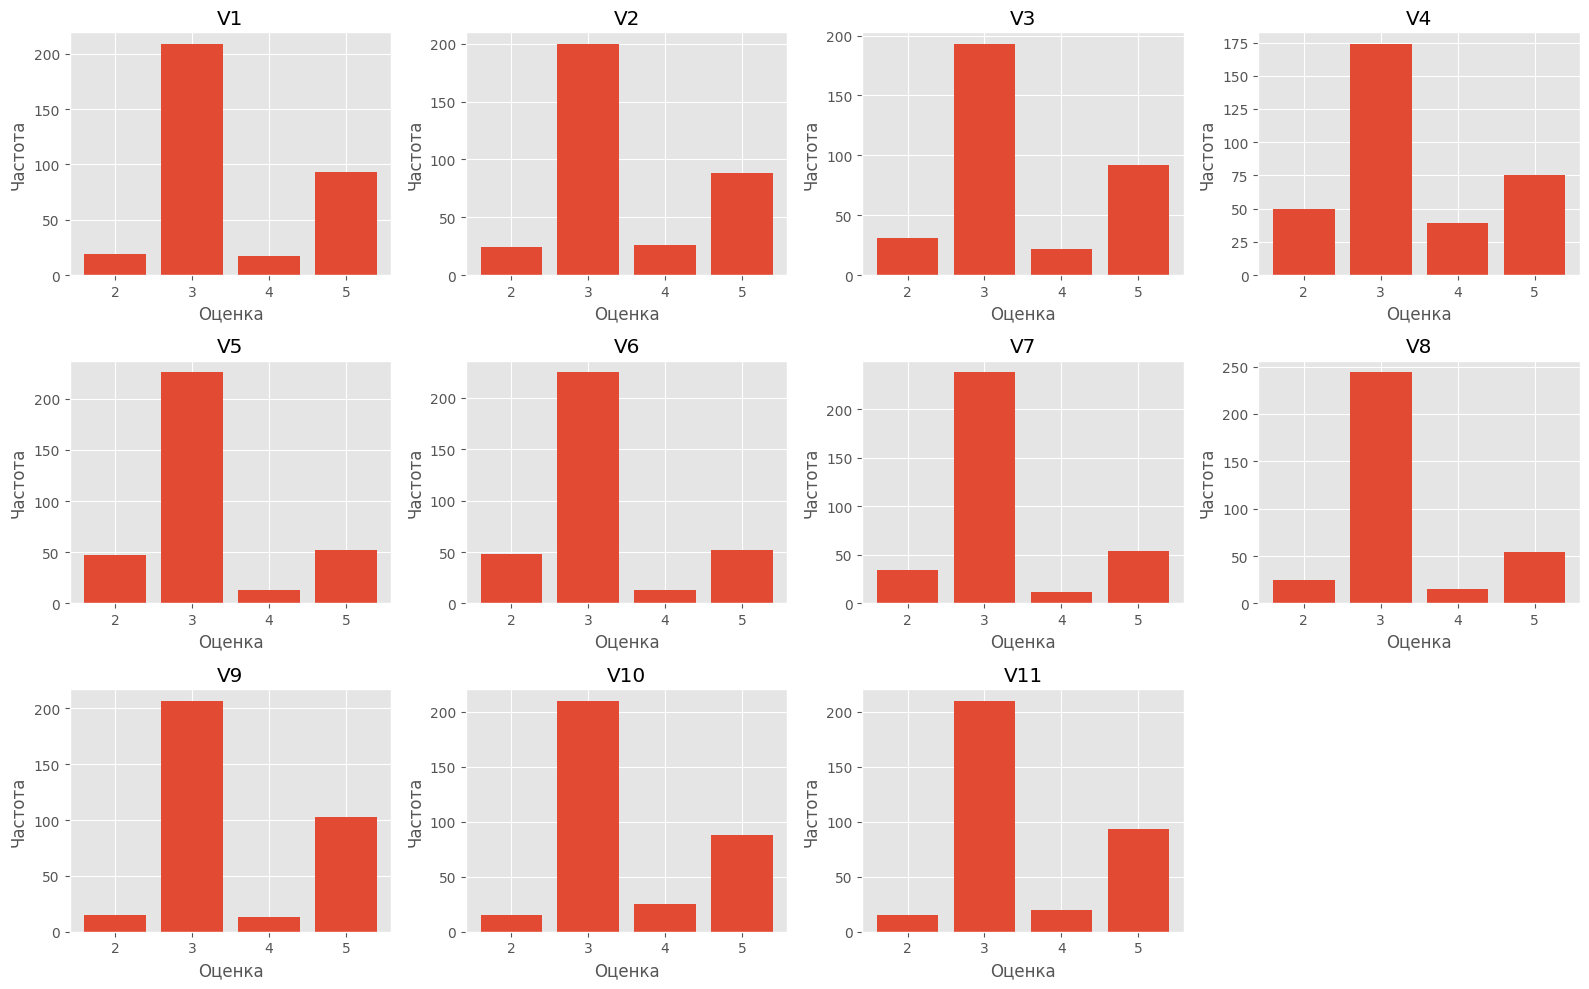

In [62]:
# Гистограммы значений для каждого признака
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.ravel()
for i, col in enumerate(df.columns):
    counts = df[col].value_counts().sort_index()
    axes[i].bar(counts.index, counts.values, )
    axes[i].set_title(col)
    axes[i].set_xticks([2, 3, 4, 5])
    axes[i].set_xlabel('Оценка')
    axes[i].set_ylabel('Частота')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

In [63]:
# Стандартизуем данные
stand = preprocessing.StandardScaler()
# Вычисляем параметры стандартизации
stand.fit(df)
# Преобразуем данные в стандартизированные
x = stand.transform(df)
x = pd.DataFrame(x, index = df.index, columns=df.columns)

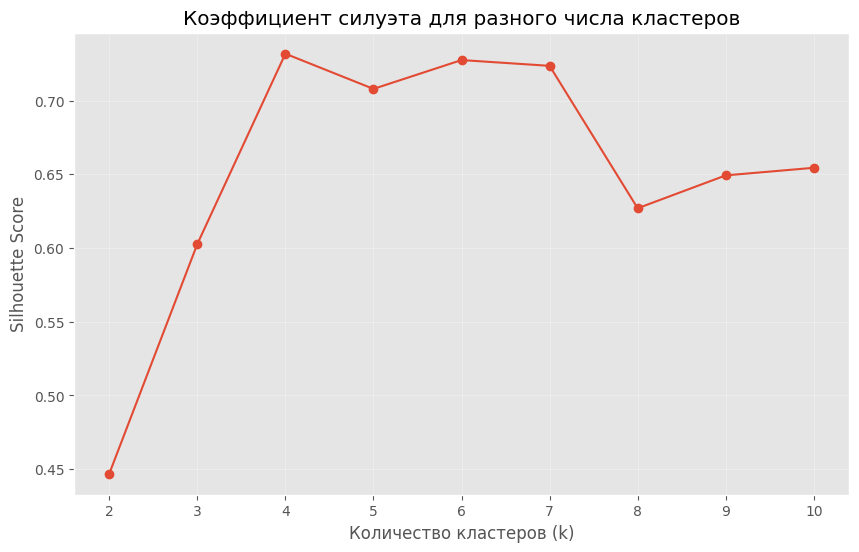

In [64]:
# Проверяем силует кластеризации для k от 2 до 10
K = range(2, 11)
silhouette_scores = []

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=68,
        max_iter=300,
        n_init=10
    )

    labels = model.fit_predict(x)

    score = silhouette_score(x, labels)
    silhouette_scores.append(score)

# Строим график зависимости коэффициента силуэта от k
plt.figure(figsize=(10, 6))

plt.plot(
    K,
    silhouette_scores,
    marker='o'
)

plt.title('Коэффициент силуэта для разного числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(list(K))
plt.grid(True, alpha=0.3)

plt.show()

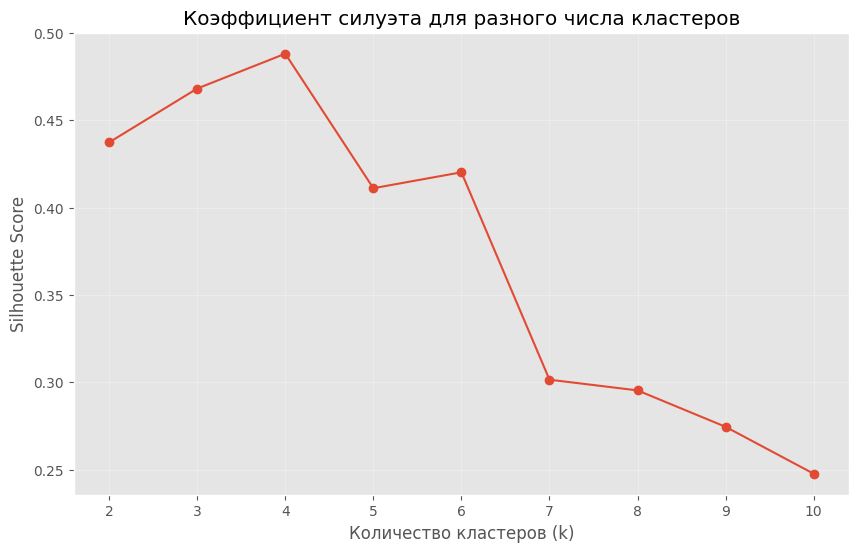

In [65]:
# Выполним аналогичный анализ силуета на данных без дублей, которые искуственно его завышают
x_uniq = x.copy()
x_uniq = x_uniq.drop_duplicates()

K = range(2, 11)
silhouette_scores = []

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=68,
        max_iter=300,
        n_init=10
    )

    labels = model.fit_predict(x_uniq)

    score = silhouette_score(x_uniq, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(10, 6))

plt.plot(
    K,
    silhouette_scores,
    marker='o'
)

plt.title('Коэффициент силуэта для разного числа кластеров')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.xticks(list(K))
plt.grid(True, alpha=0.3)

plt.show()

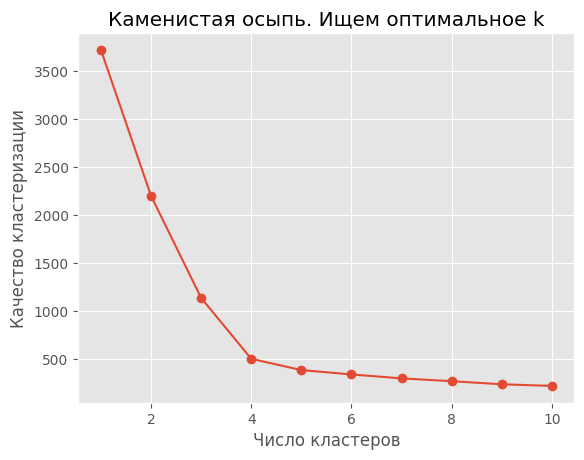

In [66]:
# Строим 10 моделей с числом кластеров от 1 до 10.
K = range(1, 11)

models = [KMeans(n_clusters=k, random_state=68, n_init=10, verbose=0).fit(x) for k in K]

#  Качество кластеризации вычисляется в model.inertia_
dist = [model.inertia_ for model in models]

# Строим график каменистая осыпь
plt.plot(K, dist, marker='o')
# Добавляем на график текст
plt.xlabel('Число кластеров')
plt.ylabel('Качество кластеризации')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

In [67]:
# На основе работы с каменистой осыпью и силуетами можем сделать вывод, что нам необходимо искать 4 кластера
# Инициализируем и обучаем модель KMeans с 4 кластерами
model = KMeans(
    n_clusters=4,
    random_state=68,
    max_iter=300,
    n_init=10,
    verbose=0)

model.fit(x)
# Сохраняем метки кластеров и группируем данные по ним, считаем mean
x['cluster'] = model.labels_
x.groupby('cluster').mean()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
0,1.363335,1.333383,1.333705,1.282320,-0.197149,-0.193196,-0.301875,-0.364421,-0.548231,-0.545356,-0.552422
1,-0.754772,-0.725967,-0.757809,-0.798182,-0.688185,-0.714857,-0.598485,-0.454898,1.394431,1.366000,1.377799
2,-0.570428,-0.551446,-0.523678,-0.415044,1.899885,1.898026,-0.301875,-0.453233,-0.877309,-0.860094,-0.862162
3,-0.570428,-0.586942,-0.557964,-0.500573,-0.336993,-0.293619,1.970459,1.980719,-0.623343,-0.594459,-0.600745


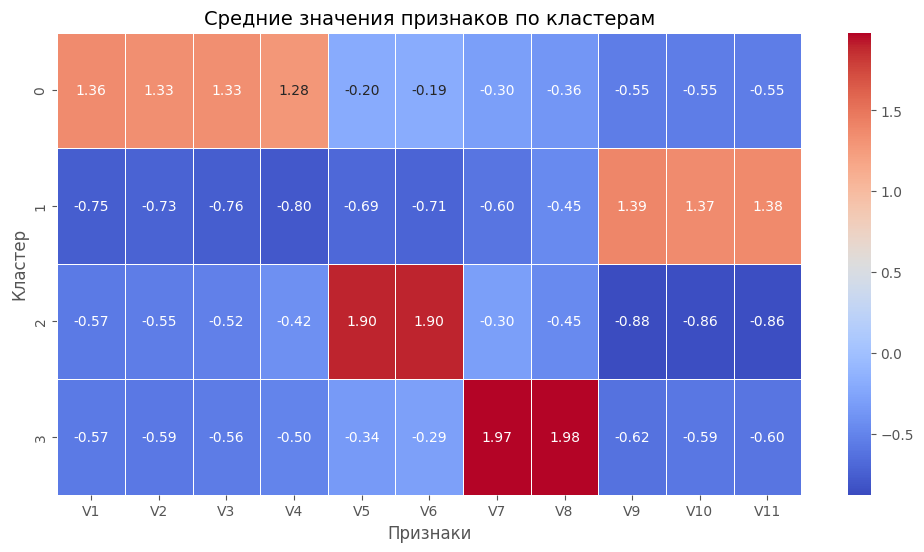

In [68]:
# Строим хитмап для большей наглядности
cluster_means = x.groupby('cluster')[x.columns.drop('cluster')].mean()
plt.figure(figsize=(12, 6))
sns.heatmap(cluster_means,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            linewidths=.5)
plt.title('Средние значения признаков по кластерам', fontsize=14)
plt.xlabel('Признаки')
plt.ylabel('Кластер')

plt.show()

In [69]:
# Проведём оценку компактности кластеров
clusters = model.fit_predict(x)
# Получаем центроиды в исходном пространстве 11 признаков
centroids = model.cluster_centers_

# Считаем евклидовы расстояния до центроидов своих кластеров
distances = np.linalg.norm(
    x.to_numpy() - centroids[clusters],
    axis=1
)

cluster_distances = pd.DataFrame({
    'Cluster': clusters,
    'Distance': distances
})

# Агреггируем данные
cluster_stats = cluster_distances.groupby('Cluster').agg(
    Количество=('Distance', 'size'),
    Среднее_расстояние=('Distance', 'mean')
)

print("Общее среднее расстояние:",
      round(distances.mean(), 3))

print("\nКомпактность кластеров:")
display(cluster_stats.round(3))


Общее среднее расстояние: 1.015

Компактность кластеров:


,Количество,Среднее_расстояние
Cluster,,
0,110,0.887
1,108,1.527
2,59,0.425
3,61,0.910


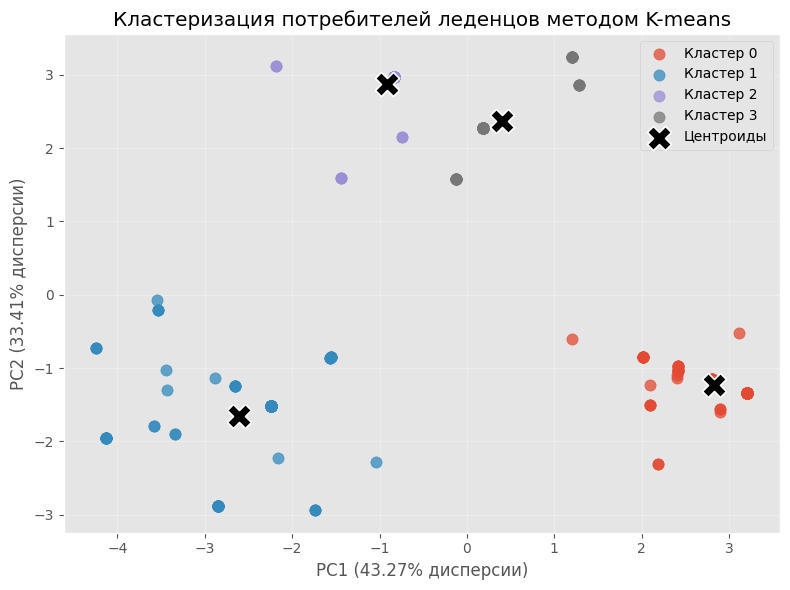

Суммарная объяснённая дисперсия: 76.69%


In [70]:
# Понижаем размерности для визуализации
pca = PCA(n_components=2)

X_pca = pca.fit_transform(x)

# Преобразуем центроиды тем же PCA
centroids_pca = pca.transform(
    pd.DataFrame(centroids, columns=x.columns)
)

# Считаем долю объяснённой дисперсии
variance = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 6))

# Строим кластеры циклом
for i in range(4):
    plt.scatter(
        X_pca[clusters == i, 0],
        X_pca[clusters == i, 1],
        s=65,
        alpha=0.75,
        label=f'Кластер {i}'
    )

# Отдельно строим центроиды
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c='black',
    marker='X',
    s=300,
    edgecolors='white',
    linewidths=1.2,
    label='Центроиды',
    zorder=10
)

plt.title('Кластеризация потребителей леденцов методом K-means')
plt.xlabel(f'PC1 ({variance[0]:.2f}% дисперсии)')
plt.ylabel(f'PC2 ({variance[1]:.2f}% дисперсии)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

print(f'Суммарная объяснённая дисперсия: {variance.sum():.2f}%')